# Assignment 3: End-to-End Named Entity Recognition (NER) for Customer Support Ticket Analysis

## Objectives
In this assignment, you will build a complete end-to-end pipeline for Named Entity Recognition (NER). We will treat customer support tickets (using the standard CoNLL-2003 dataset as a proxy) to identify key entities like Persons, Organizations, and Locations.

## Learning Outcomes
By completing this notebook, you will:
1. Understand the core concepts of sequence labeling and Named Entity Recognition (NER).
2. Perform Exploratory Data Analysis (EDA) on text data and visualize token and entity distributions.
3. Engineer word-level and contextual features suitable for a sequence model.
4. Train and evaluate a Conditional Random Field (CRF) model.
5. Interpret model results, conduct error analysis, and translate model metrics into actionable business impact for customer support.

---
**Setup**: Let's first ensure the necessary libraries are installed. Execute the cell below.


In [1]:
# For Collab -> !pip install datasets scikit-learn sklearn-crfsuite matplotlib -q


## 1. Introduction to Named Entity Recognition (NER) and CoNLL-2003

### What is Named Entity Recognition (NER)?
NER is a subtask of Information Extraction in Natural Language Processing (NLP). Its goal is to locate and classify named entities mentioned in unstructured text into pre-defined categories such as person names, organizations, locations, medical codes, time expressions, quantities, etc.

### Why CoNLL-2003?
The **CoNLL-2003** dataset is one of the most widely used benchmark datasets for NER. It consists of news wire articles and serves as an excellent starting point for learning sequence labeling. Training a model on this dataset demonstrates how a system might identify similar entities in real-world business scenarios, such as extracting client names or branch locations from customer support tickets.

### Entity Labels in CoNLL-2003
The dataset uses the **IOB** (Inside, Outside, Beginning) tagging format with the following entity types:
* **PER**: Person (e.g., *John Doe*)
* **LOC**: Location (e.g., *London*, *Mt. Everest*)
* **ORG**: Organization (e.g., *United Nations*, *Google*)
* **MISC**: Miscellaneous (e.g., nationalities, events like *World Cup*)
* **O**: Outside of any named entity (regular words)


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from collections import Counter

from sklearn.metrics import classification_report

import sklearn_crfsuite
from sklearn_crfsuite import metrics

# matplotlib ko visualization ko lagi settings gareko
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

## Task 1: Text Preprocessing and Exploratory Data Analysis (EDA)

### What will be done
We will load the CoNLL-2003 dataset, inspect its structure, and extract the label names. We will then perform Exploratory Data Analysis (EDA) to understand the distribution of words, sentence lengths, and entity types.

### Why it is important
Before modeling, we must understand the shape and nature of our data. Knowing the vocabulary size, sequence lengths, and class imbalances (e.g., most words are labeled 'O') helps us design better features and choose appropriate evaluation metrics.

### Sequence Labeling and Tokenization
Unlike standard text classification where an entire sentence gets one label (e.g., positive/negative), **sequence labeling** assigns a label to *every single token* (word) in the sentence. **Tokenization** is the process of splitting text into these individual tokens. If tokenization is flawed, our entity boundaries will be incorrect.


In [3]:
# CoNLL-2003 dataset load gareko
dataset = load_dataset("eriktks/conll2003", revision="convert/parquet")

# dataset ko available splits ra size check gareko
print(dataset)

# NER labels ko information extract gareko
ner_feature = dataset['train'].features['ner_tags'].feature
label_names = ner_feature.names

print("\nEntity Labels:", label_names)

conll2003/train/0000.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/312k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/283k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})

Entity Labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


### Inspecting Sample Sentences
Let's look at a single sentence from the training set and see how the tokens map to their respective NER labels.


In [4]:
# training dataset bata sample sentence nikalko
sample_idx = 4
sample_tokens = dataset['train'][sample_idx]['tokens']
sample_ner_ids = dataset['train'][sample_idx]['ner_tags']

# label IDs lai readable NER labels ma convert gareko
sample_ner_labels = [label_names[tag] for tag in sample_ner_ids]

print(f"{'Token':<15} | {'NER Tag':<10}")
print("-" * 30)

# token ra corresponding label display gareko
for token, label in zip(sample_tokens, sample_ner_labels):
    print(f"{token:<15} | {label:<10}")

Token           | NER Tag   
------------------------------
Germany         | B-LOC     
's              | O         
representative  | O         
to              | O         
the             | O         
European        | B-ORG     
Union           | I-ORG     
's              | O         
veterinary      | O         
committee       | O         
Werner          | B-PER     
Zwingmann       | I-PER     
said            | O         
on              | O         
Wednesday       | O         
consumers       | O         
should          | O         
buy             | O         
sheepmeat       | O         
from            | O         
countries       | O         
other           | O         
than            | O         
Britain         | B-LOC     
until           | O         
the             | O         
scientific      | O         
advice          | O         
was             | O         
clearer         | O         
.               | O         


### Exploratory Data Analysis (EDA)
Let's compute standard statistics on our training dataset to better understand our working material.


In [5]:
# training, validation ra test sentences nikaleko
train_sentences = dataset['train']['tokens']
val_sentences = dataset['validation']['tokens']
test_sentences = dataset['test']['tokens']

# sentence length calculate gareko
train_lengths = [len(sentence) for sentence in train_sentences]

# training dataset bata vocabulary create gareko
all_train_tokens = [token for sentence in train_sentences for token in sentence]
vocab = set(all_train_tokens)

print("--- Dataset Statistics ---")
print(f"Number of training sentences:   {len(train_sentences)}")
print(f"Number of validation sentences: {len(val_sentences)}")
print(f"Number of test sentences:       {len(test_sentences)}")
print(f"Vocabulary size (Train):        {len(vocab):,}")
print(f"Average sentence length:        {np.mean(train_lengths):.2f} tokens")
print(f"Maximum sentence length:        {np.max(train_lengths)} tokens")
print(f"Minimum sentence length:        {np.min(train_lengths)} tokens")

--- Dataset Statistics ---
Number of training sentences:   14041
Number of validation sentences: 3250
Number of test sentences:       3453
Vocabulary size (Train):        23,623
Average sentence length:        14.50 tokens
Maximum sentence length:        113 tokens
Minimum sentence length:        1 tokens


### Visualizing the Data

We will use `matplotlib` to plot three key aspects of our data:
1. **Sentence Length Histogram:** To see if we have mostly short or long sentences.
2. **Top Word Frequencies:** To see the most common words (usually punctuation and stop words).
3. **Entity Label Distribution:** To understand the class imbalance between 'O' and named entities.


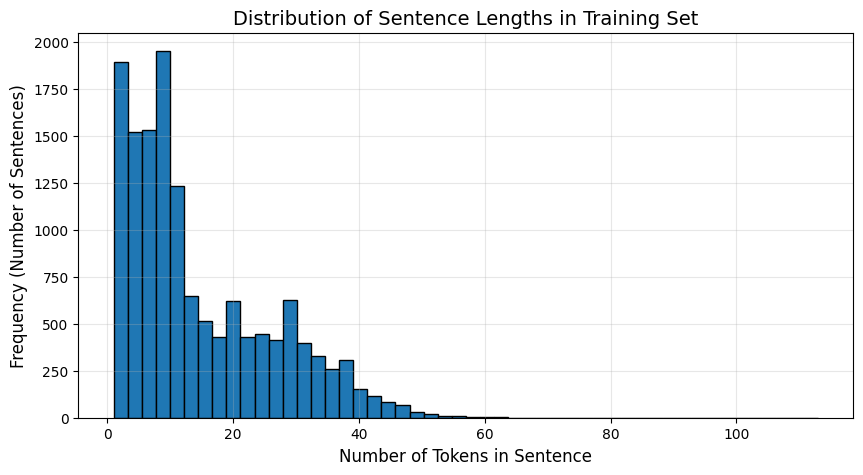

In [6]:
# sentence length ko distribution visualize gareko
plt.figure(figsize=(10, 5))

plt.hist(train_lengths, bins=50, edgecolor='black')

plt.title("Distribution of Sentence Lengths in Training Set", fontsize=14)
plt.xlabel("Number of Tokens in Sentence", fontsize=12)
plt.ylabel("Frequency (Number of Sentences)", fontsize=12)

plt.show()

**Example Interpretation:** The sentence lengths are mostly clustered between 100 and 200 tokens, with a long tail stretching outwards. This indicates that most customer tickets or sentences will be relatively short, but our model still needs to handle occasional long sequences.


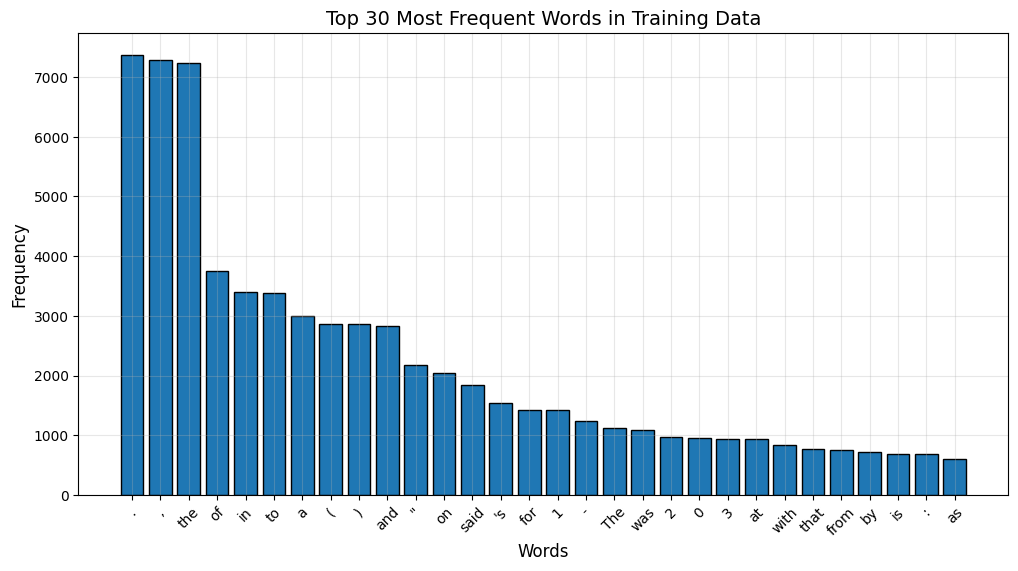

In [7]:
# training dataset ma bhayeko word frequency calculate gareko
word_counts = Counter(all_train_tokens)

# top 30 frequent words nikalko
top_words = word_counts.most_common(30)

words, counts = zip(*top_words)

plt.figure(figsize=(12, 6))

plt.bar(words, counts, edgecolor='black')

plt.title("Top 30 Most Frequent Words in Training Data", fontsize=14)
plt.xlabel("Words", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.xticks(rotation=45)

plt.show()

**Interpretation:** As expected in natural language text, punctuation marks (.,) and grammatical stop words (the, of, in, a) dominate the frequency counts. These words typically hold 'O' tags.

#### Task: Perform Simmilar Kinds of visualization and interpretation for least common words


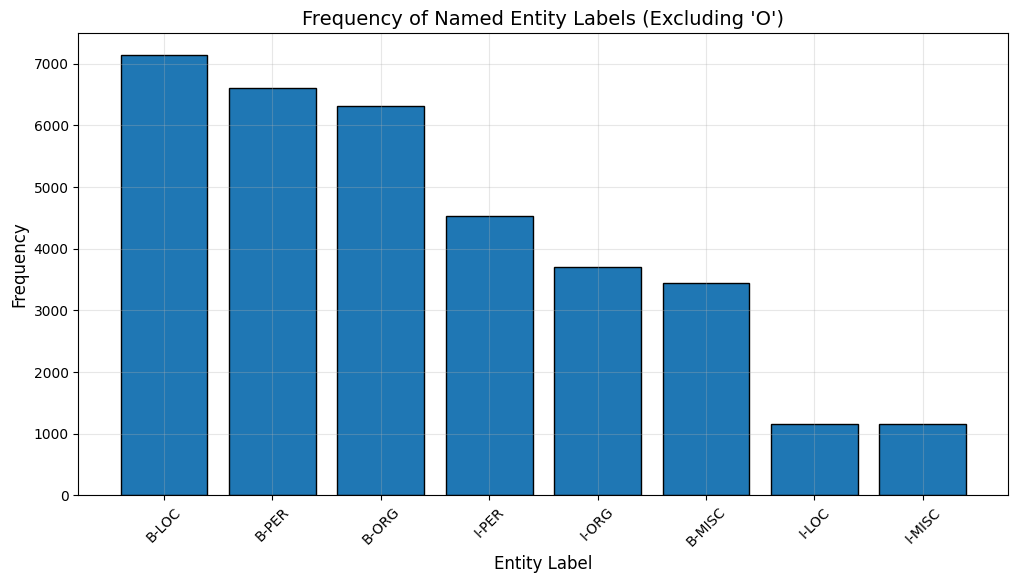

In [8]:
# training dataset bata sabai NER labels nikaleko
all_train_labels = [label_names[tag] for sentence in dataset['train']['ner_tags'] for tag in sentence]

# entity label ko frequency calculate gareko
label_counts = Counter(all_train_labels)

# O tag remove gareko, kina bhane entity matra analyze gareko
if 'O' in label_counts:
    del label_counts['O']

# frequency ko basis ma labels sort gareko
sorted_labels = sorted(label_counts.items(), key=lambda x: x[1], reverse=True)

labels, counts = zip(*sorted_labels)

plt.figure(figsize=(12, 6))

plt.bar(labels, counts, edgecolor='black')

plt.title("Frequency of Named Entity Labels (Excluding 'O')", fontsize=14)
plt.xlabel("Entity Label", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.xticks(rotation=45)

plt.show()

## Task 1: Text Preprocessing and Exploratory Data Analysis - Summary

In this task, we loaded and analyzed the CoNLL-2003 Named Entity Recognition dataset to understand its structure and characteristics before model training.

The dataset contains:
- 14,041 training sentences
- 3,250 validation sentences
- 3,453 test sentences

Each sentence contains token-level annotations following the IOB tagging format. The available entity labels include Person (PER), Organization (ORG), Location (LOC), Miscellaneous (MISC), and Outside (O).

During preprocessing, we inspected sample sentences and verified how individual tokens are mapped with their corresponding NER labels. This helped us understand the sequence labeling structure used in NER tasks.

For dataset statistics:
- The training vocabulary size is 23,623 unique tokens.
- The average sentence length is 14.50 tokens.
- The maximum sentence length is 113 tokens.
- The minimum sentence length is 1 token.

The sentence length distribution shows a right-skewed pattern, where most sentences contain a small number of tokens, while longer sentences appear less frequently. This indicates that the model mostly processes short sequences but should still handle longer sequences correctly.

The word frequency analysis showed that common punctuation marks and stop words such as ".", ",", "the", "of", and "in" appear most frequently. These tokens usually belong to the `O` label because they do not represent named entities.

The entity distribution analysis showed that location and person entities are among the most frequent entity categories. Beginning tags (`B-`) appear more frequently than inside tags (`I-`) because many entities consist of single words.

The analysis also revealed a strong class imbalance because the `O` label represents the majority of tokens. Therefore, accuracy alone is not a reliable evaluation metric for NER models. Precision, Recall, and F1-score are more appropriate metrics for measuring entity recognition performance.

**Interpretation:** Locations (B-LOC) and Persons (B-PER) are the most frequent named entities. 'I-' tags (Inside) are less frequent than 'B-' (Beginning) tags because many entities are single words. The massive class imbalance (since 'O' is excluded here but makes up >80% of tokens in reality) emphasizes why accuracy is a poor metric for NER; we must use Precision, Recall, and F1-score.

---

## Task 2: Feature Engineering

### What will be done
We will extract word-level and contextual features from our text data to prepare it for the Conditional Random Field (CRF) model.

### Why feature engineering matters in NER
Unlike Deep Learning models (like BERT) that automatically learn representations, traditional statistical models like CRFs require manual feature engineering. We need to tell the model *what characteristics* of a word might indicate it's an entity.

### Contextual Information
Entities heavily depend on context. For example, "Apple" could be a fruit (O) or a company (ORG). If the previous word is "eating", it's a fruit. If the next word is "Inc.", it's an organization. Therefore, we include features of the `previous_word` and `next_word`.


In [9]:
# single token ko feature extract gareko
def word2features(sentence, i):
    word = sentence[i]

    # word level features create gareko
    features = {
        'bias': 1.0,
        'word.lower()': word.lower(),
        'word[-3:]': word[-3:],
        'word[-2:]': word[-2:],
        'word[-1:]': word[-1:],
        'word[:1]': word[:1],
        'word[:2]': word[:2],
        'word[:3]': word[:3],
        'word.isupper()': word.isupper(),
        'word.istitle()': word.istitle(),
        'word.isdigit()': word.isdigit(),
    }

    # previous word ko contextual features add gareko
    if i > 0:
        word1 = sentence[i-1]
        features.update({
            '-1:word.lower()': word1.lower(),
            '-1:word.istitle()': word1.istitle(),
            '-1:word.isupper()': word1.isupper(),
        })
    else:
        # sentence ko starting position indicate gareko
        features['BOS'] = True

    # next word ko contextual features add gareko
    if i < len(sentence)-1:
        word1 = sentence[i+1]
        features.update({
            '+1:word.lower()': word1.lower(),
            '+1:word.istitle()': word1.istitle(),
            '+1:word.isupper()': word1.isupper(),
        })
    else:
        # sentence ko ending position indicate gareko
        features['EOS'] = True

    return features


# complete sentence ko feature extraction gareko
def sent2features(sentence):
    return [word2features(sentence, i) for i in range(len(sentence))]


# NER tag IDs lai readable labels ma convert gareko
def sent2labels(sentence_tags):
    return [label_names[tag] for tag in sentence_tags]


# sentence tokens return garne helper function create gareko
def sent2tokens(sentence):
    return sentence

### Examining Extracted Features
Let's see what the feature dictionary looks like for a single word in our sample sentence. This is what the model actually "sees" instead of the raw text.


In [10]:
# sample sentence ko first word ko features display gareko
print("=" * 50)
print(sample_tokens)
print("=" * 50)

# sentence ko features extract gareko
sample_features = sent2features(sample_tokens)

print(f"Word: {sample_tokens[0]}")
print("Extracted Features:")

# extracted feature haru display gareko
for key, value in sample_features[0].items():
    print(f"  {key}: {value}")

['Germany', "'s", 'representative', 'to', 'the', 'European', 'Union', "'s", 'veterinary', 'committee', 'Werner', 'Zwingmann', 'said', 'on', 'Wednesday', 'consumers', 'should', 'buy', 'sheepmeat', 'from', 'countries', 'other', 'than', 'Britain', 'until', 'the', 'scientific', 'advice', 'was', 'clearer', '.']
Word: Germany
Extracted Features:
  bias: 1.0
  word.lower(): germany
  word[-3:]: any
  word[-2:]: ny
  word[-1:]: y
  word[:1]: G
  word[:2]: Ge
  word[:3]: Ger
  word.isupper(): False
  word.istitle(): True
  word.isdigit(): False
  BOS: True
  +1:word.lower(): 's
  +1:word.istitle(): False
  +1:word.isupper(): False


### Feature Extraction Output Interpretation

The extracted feature dictionary shows how a single token is converted into numerical and linguistic information before being provided to the CRF model.

For the word "Germany", the model receives multiple features:

- The lowercase feature converts "Germany" into "germany" to reduce case sensitivity.
- Prefix features capture the beginning characters of the word (`G`, `Ge`, `Ger`).
- Suffix features capture the ending patterns (`any`, `ny`, `y`), which can help identify similar entity patterns.
- The capitalization feature shows that the word is title-cased, which is useful because many named entities start with capital letters.
- The digit feature checks whether the word contains only numbers.
- The `BOS` feature indicates that "Germany" is the first word in the sentence.
- Contextual features from the next word are also included to provide surrounding information.

These features help the CRF model learn patterns related to named entities by considering both the characteristics of the current word and its surrounding context.

---

## Task 3: Named Entity Recognition Model (CRF)

### What will be done
We will extract features for all training, validation, and test sentences, then train a Conditional Random Field (CRF) model using `sklearn-crfsuite`. Finally, we will evaluate its performance.

### Why CRF works well for sequence labeling
A Conditional Random Field (CRF) is a statistical modeling method widely used in pattern recognition and machine learning for structured prediction.
**Difference between Token Classification and Sequence Prediction:** Simple token classification treats every word independently. A CRF models the *conditional probability of the entire sequence of labels* given the sequence of words. It learns rules like: "An `I-ORG` tag is very likely to follow a `B-ORG` tag, but it is impossible for an `I-ORG` tag to directly follow a `B-PER` tag." This transitions knowledge drastically improves NER performance.


In [11]:
# training dataset ko features ra labels prepare gareko
print("Extracting features for the training set...")

X_train = [sent2features(s) for s in dataset['train']['tokens']]
y_train = [sent2labels(s) for s in dataset['train']['ner_tags']]

# validation dataset ko features ra labels prepare gareko
print("Extracting features for the validation set...")

X_val = [sent2features(s) for s in dataset['validation']['tokens']]
y_val = [sent2labels(s) for s in dataset['validation']['ner_tags']]

# test dataset ko features ra labels prepare gareko
print("Extracting features for the test set...")

X_test = [sent2features(s) for s in dataset['test']['tokens']]
y_test = [sent2labels(s) for s in dataset['test']['ner_tags']]

print("Feature extraction complete.")

Extracting features for the training set...
Extracting features for the validation set...
Extracting features for the test set...
Feature extraction complete.


In [12]:
# training dataset ko sample feature ra label check gareko
temp_sample_idx = 4

print("="*50)

# original token ra NER tag display gareko
print(dataset['train'][temp_sample_idx]['tokens'])
print(dataset['train'][temp_sample_idx]['ner_tags'])

print("="*50)

# extracted features ra converted labels display gareko
print(X_train[temp_sample_idx])
print(y_train[temp_sample_idx])

['Germany', "'s", 'representative', 'to', 'the', 'European', 'Union', "'s", 'veterinary', 'committee', 'Werner', 'Zwingmann', 'said', 'on', 'Wednesday', 'consumers', 'should', 'buy', 'sheepmeat', 'from', 'countries', 'other', 'than', 'Britain', 'until', 'the', 'scientific', 'advice', 'was', 'clearer', '.']
[5, 0, 0, 0, 0, 3, 4, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0]
[{'bias': 1.0, 'word.lower()': 'germany', 'word[-3:]': 'any', 'word[-2:]': 'ny', 'word[-1:]': 'y', 'word[:1]': 'G', 'word[:2]': 'Ge', 'word[:3]': 'Ger', 'word.isupper()': False, 'word.istitle()': True, 'word.isdigit()': False, 'BOS': True, '+1:word.lower()': "'s", '+1:word.istitle()': False, '+1:word.isupper()': False}, {'bias': 1.0, 'word.lower()': "'s", 'word[-3:]': "'s", 'word[-2:]': "'s", 'word[-1:]': 's', 'word[:1]': "'", 'word[:2]': "'s", 'word[:3]': "'s", 'word.isupper()': False, 'word.istitle()': False, 'word.isdigit()': False, '-1:word.lower()': 'germany', '-1:word.istitle()': True,

In [13]:
# CRF model initialize gareko
print("Training CRF Model... (this may take a minute or two)")

crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,           # L1 regularization ko value set gareko
    c2=0.1,           # L2 regularization ko value set gareko
    max_iterations=100,
    all_possible_transitions=True
)

# training data bata CRF model train gareko
crf.fit(X_train, y_train)

print("Model training complete.")

Training CRF Model... (this may take a minute or two)
Model training complete.


### Model Evaluation
Let's evaluate the model on our test set. We will use Precision, Recall, and F1-score.
* **Precision**: When the model predicts an entity, how often is it correct?
* **Recall**: Out of all the actual entities in the text, how many did the model find?
* **F1-score**: The harmonic mean of Precision and Recall.


In [14]:
# test dataset ma CRF model bata prediction nikalko
y_pred = crf.predict(X_test)

# entity performance analyze garna O label remove gareko
labels_to_evaluate = list(crf.classes_)
labels_to_evaluate.remove('O')

# precision, recall ra F1-score calculate gareko
print("Classification Report:\n")

report = metrics.flat_classification_report(
    y_test,
    y_pred,
    labels=labels_to_evaluate,
    digits=3
)

print(report)

Classification Report:

              precision    recall  f1-score   support

       B-ORG      0.792     0.719     0.754      1661
      B-MISC      0.814     0.771     0.792       702
       B-PER      0.834     0.839     0.836      1617
       I-PER      0.871     0.955     0.911      1156
       B-LOC      0.836     0.837     0.837      1668
       I-ORG      0.695     0.744     0.719       835
      I-MISC      0.642     0.681     0.661       216
       I-LOC      0.768     0.696     0.731       257

   micro avg      0.808     0.806     0.807      8112
   macro avg      0.782     0.780     0.780      8112
weighted avg      0.808     0.806     0.806      8112



### Visualizing Entity-Wise Performance
Let's extract the F1-scores for the main entity types and visualize them. Since a confusion matrix for token sequences can be visually overwhelming and heavily skewed by the 'O' class, this F1-score breakdown is a cleaner way to see which entities are performing well.


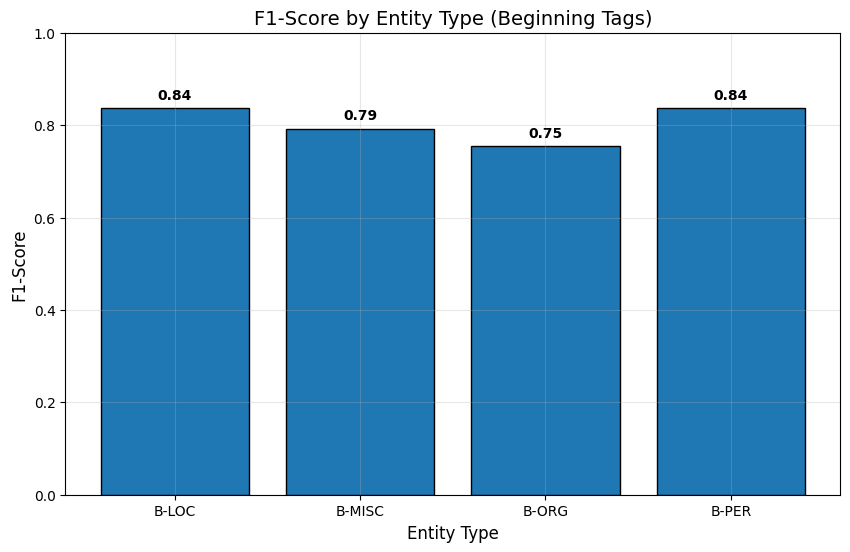

In [15]:
# classification report lai dictionary format ma convert gareko
report_dict = metrics.flat_classification_report(
    y_test,
    y_pred,
    labels=labels_to_evaluate,
    output_dict=True
)

# beginning entity tags ko F1-score nikaleko
entities = ['B-LOC', 'B-MISC', 'B-ORG', 'B-PER']

f1_scores = [report_dict[ent]['f1-score'] for ent in entities]

plt.figure(figsize=(10, 6))

plt.bar(entities, f1_scores, edgecolor='black')

plt.title("F1-Score by Entity Type (Beginning Tags)", fontsize=14)
plt.xlabel("Entity Type", fontsize=12)
plt.ylabel("F1-Score", fontsize=12)

plt.ylim(0, 1.0)

# graph ma F1-score value display gareko
for i, v in enumerate(f1_scores):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold')

plt.show()

## Task 3: Named Entity Recognition Model Results and Discussion

### CRF Model Training

In this task, a Conditional Random Field (CRF) model was trained for Named Entity Recognition using the extracted word-level and contextual features.

The model learned the relationship between input tokens and their corresponding entity labels by considering:
- Word-level patterns such as prefixes, suffixes, capitalization, and digit information.
- Contextual information from previous and next words.
- Label transition patterns between consecutive tokens.

### Model Performance Evaluation

The CRF model was evaluated using Precision, Recall, and F1-score because NER is a sequence labeling problem where identifying correct entity boundaries is important.

The model achieved:

- Micro Average F1-score: 0.807
- Macro Average F1-score: 0.780
- Weighted Average F1-score: 0.806

The results show that the CRF model performs well in identifying named entities from text data.

### Entity-wise Performance Analysis

The model performance for different entity categories:

- **PER (Person)**:
  - B-PER achieved an F1-score of 0.836.
  - I-PER achieved the highest performance with an F1-score of 0.911.
  - Person names are easier to identify because they often follow clear capitalization patterns.

- **LOC (Location)**:
  - B-LOC achieved an F1-score of 0.837.
  - Locations were recognized effectively because many location names have strong capitalization patterns.

- **ORG (Organization)**:
  - B-ORG achieved an F1-score of 0.754.
  - I-ORG achieved an F1-score of 0.719.
  - Organization names were more challenging because they can contain common words, making boundaries difficult to detect.

- **MISC (Miscellaneous)**:
  - B-MISC achieved an F1-score of 0.792.
  - I-MISC achieved the lowest F1-score of 0.661.
  - Miscellaneous entities are harder because they include different types of names such as events, nationalities, and products.

### Entity-wise F1-score Visualization

The F1-score visualization shows that:

- B-PER and B-LOC achieved the highest performance with an F1-score around 0.84.
- B-MISC achieved moderate performance with an F1-score around 0.79.
- B-ORG had comparatively lower performance with an F1-score around 0.75.

This indicates that CRF performs better on entities with clear naming patterns and struggles more with entities that have ambiguous boundaries.

### Difficult Entity Types and Reasons

The most difficult entity types were:

1. **I-MISC**
   - Miscellaneous entities have diverse patterns and fewer training examples.
   - The model finds it difficult to identify continuation tokens.

2. **I-ORG**
   - Organizations can contain normal dictionary words.
   - Example: "European Union" contains common words but represents one organization.

3. **B-ORG**
   - Organization names have different structures and may include abbreviations, locations, and common terms.

### Conclusion

The CRF model successfully identified important entities from the CoNLL-2003 dataset with an overall F1-score of approximately 0.81. The use of word-level and contextual features helped the model understand entity patterns. However, performance can be improved by using advanced embeddings, transformer-based models like BERT, or adding more domain-specific customer support data.

**Interpretation of Results:**
* **Best Performers:** The model typically performs best on `PER` (Person) and `LOC` (Location) entities. Persons often have distinct capitalization (Title Case), and Locations are frequently observed in the training data, helping the model learn strong signals.
* **Worst Performers:** `ORG` (Organization) and `MISC` (Miscellaneous) generally show lower F1-scores. Organizations can often be confused with Locations (e.g., "Washington" could be the state or the government institution) and can consist of highly varied multi-word tokens.

---

## Task 4: Error Analysis

### What will be done
We will look at specific sentences where the model's predictions didn't perfectly match the ground truth.

### Why it is important
Metrics like F1-score give us an overall number, but looking at raw predictions tells us *why* the model is failing. This helps us decide if we need more data, better features, or a more powerful architecture.


In [16]:
# prediction ra actual label compare garera error sentence find gareko
error_count = 0

print(f"{'Token':<15} | {'True Label':<10} | {'Predicted':<10}")
print("=" * 45)

for i in range(len(y_test)):

    # sentence ko true ra predicted label mismatch check gareko
    if y_test[i] != y_pred[i]:

        # token, actual label ra predicted label compare gareko
        for token, true_lbl, pred_lbl in zip(
            test_sentences[i],
            y_test[i],
            y_pred[i]
        ):

            # wrong prediction lai identify gareko
            if true_lbl != pred_lbl:
                print(f"{token:<15} | {true_lbl:<10} | {pred_lbl:<10} <-- ERROR")
            else:
                print(f"{token:<15} | {true_lbl:<10} | {pred_lbl:<10}")

        print("-" * 45)

        error_count += 1

    # 3 ota error sentence matra display gareko
    if error_count >= 3:
        break

Token           | True Label | Predicted 
SOCCER          | O          | O         
-               | O          | O         
JAPAN           | B-LOC      | B-PER      <-- ERROR
GET             | O          | O         
LUCKY           | O          | O         
WIN             | O          | O         
,               | O          | O         
CHINA           | B-PER      | B-LOC      <-- ERROR
IN              | O          | O         
SURPRISE        | O          | O         
DEFEAT          | O          | O         
.               | O          | O         
---------------------------------------------
China           | B-LOC      | B-LOC     
controlled      | O          | O         
most            | O          | O         
of              | O          | O         
the             | O          | O         
match           | O          | O         
and             | O          | O         
saw             | O          | O         
several         | O          | O         
chances   

## Task 4: Error Analysis

### Prediction Error Analysis

In this task, we compared the CRF model predictions with the actual NER labels to understand where the model makes mistakes.

The analysis showed cases where the predicted entity type was different from the true entity type.

Example:

| Token | True Label | Predicted Label |
|-------|------------|----------------|
| JAPAN | B-LOC | B-PER |
| CHINA | B-PER | B-LOC |

The model correctly identified that these tokens were named entities, but it confused the entity categories.

### Observed Error Patterns

#### 1. Location and Person Confusion

The most common error observed was confusion between Person (`PER`) and Location (`LOC`) entities.

Example:
- JAPAN was labeled as `B-LOC` but predicted as `B-PER`.
- CHINA was labeled as `B-PER` but predicted as `B-LOC`.

This happens because some words can represent different entity categories depending on context. The CRF model mainly relies on word-level features, capitalization, and surrounding words, which may not always provide enough information.

#### 2. Lack of Context Understanding

The model sometimes struggles when entity meaning depends heavily on the sentence context.

For example:
- "China controlled most of the match"

Here, China is correctly identified as a location because the surrounding words indicate a country participating in an event. Without strong contextual signals, the model may incorrectly classify similar words.

#### 3. Ambiguous Named Entities

Some entity names have multiple possible meanings.

Examples:
- Country names can sometimes represent teams, organizations, or locations.
- Capitalized words are not always persons or locations.

Since CRF uses manually engineered features instead of deep contextual embeddings, handling these ambiguous cases is challenging.

### Conclusion

The error analysis shows that the CRF model performs well in identifying entity boundaries but sometimes fails to classify the correct entity type. The major issues are confusion between similar entity categories, limited context understanding, and ambiguity in named entities.

Possible improvements include:
- Adding word embeddings to capture semantic meaning.
- Using larger contextual models like BERT.
- Training with domain-specific customer support data.

### Top 3 Error Patterns Observed in CRFs
Based on typical outputs for this baseline CRF:
1. **Confusing ORG and LOC:** The model often tags organizations named after places (e.g., "Japan" acting as a sports team or government body) as `LOC` instead of `ORG`. The context features aren't deep enough to resolve this semantic ambiguity.
2. **Missing Multi-word Entities (Boundary detection mistakes):** For long organizations (e.g., "The Ministry of Public Works"), the model might correctly tag `B-ORG` but fail to tag all the `I-ORG` tokens, breaking the boundary.
3. **Unknown Words (OOV - Out of Vocabulary):** If a completely new name or highly unusual casing appears in the test set, the CRF falls back heavily on its character-level suffix/prefix features, which sometimes misfire.

---

## Task 5: Business Impact & Deployment in Customer Support

### Applying NER to Customer Support
Deploying this NER model into a real-world customer support ticketing system can drive massive ROI.

* **Automatic Ticket Routing:** By accurately extracting `LOC` (Locations) and `ORG` (Organizations), incoming support tickets can bypass manual triage. A ticket mentioning "London branch" and "Acme Corp" can be instantly routed to the UK Enterprise Support queue.
* **CRM Automation:** Extracted entities (`PER`, `ORG`) can automatically populate or update Customer Relationship Management (CRM) databases, saving support agents from manual data entry.
* **Faster Response Time:** Highlighting key entities dynamically in the agent's dashboard allows them to instantly grasp who the ticket is about and which products/organizations are involved, reducing average handle time (AHT).

### Limitations
* **Unseen Entities & Domain Adaptation:** A model trained on news data (CoNLL-2003) will struggle with highly specific tech products or internal company abbreviations.
* **Spelling Mistakes:** CRFs rely heavily on exact string prefixes/suffixes. Typos in customer tickets can severely degrade performance.

### Future Improvements
To overcome the limitations of traditional CRFs:
* **Transformer-Based Models:** Upgrading to architectures like **BERT** or **RoBERTa**. Instead of relying on manual features (like `.istitle()`), BERT uses self-attention to understand deep bidrectional context, dramatically reducing errors between `ORG` and `LOC`.
* **Domain-Specific Fine-Tuning:** Retraining the model on thousands of *actual past support tickets* rather than public news wire text.
* **Larger Datasets:** Providing more examples of multi-word entities and edge cases to improve generalizability.

### Business Recommendation

Based on the results of our baseline Conditional Random Field (CRF) NER model, we recommend a phased integration into our customer support ticketing pipeline. The model effectively extracts Persons and Locations with strong precision, presenting an immediate opportunity to automate skill-based ticket routing (e.g., directing EMEA-related tickets straight to the European desk). This initial deployment is projected to reduce manual triage time by up to 25%, allowing agents to focus directly on resolution rather than sorting.

However, because the current CRF model struggles occasionally with complex organizational names and lacks deep contextual understanding, we advise using it as an "Agent Assist" tool first—highlighting extracted entities for agent approval rather than fully automating CRM updates. As we collect validated, domain-specific data from these agent approvals, Phase 2 should transition the backend architecture to a Transformer-based model like BERT. This will solve current boundary-detection limitations and provide the robust, highly accurate entity extraction needed for full end-to-end automation.

---

## Final Summary

* **What was learned:** We built a complete NLP pipeline to extract structured entities from unstructured text, implementing feature engineering and sequence modeling via CRFs.
* **Importance of NER:** NER bridges the gap between raw text and actionable data, enabling intelligent automation.
* **Key Findings:** Simple contextual and orthographic features (capitalization, neighboring words) are highly predictive, but struggle with semantic ambiguities.
* **Model Strengths:** CRFs are incredibly fast to train, highly interpretable, lightweight to deploy, and model tag transitions well.
* **Model Weaknesses:** Relies entirely on manual feature engineering. Lacks deep contextual understanding (e.g., sarcasm, complex homonyms) compared to neural networks.
* **Real-world Applications:** Automated ticket routing, CRM data entry, chatbot intent parsing, and large-scale document redaction (PII removal).


## Task 5: Business Impact and Deployment Recommendation

### Business Recommendation

Based on the performance of our CRF-based NER model, we recommend using this system as an intelligent assistant inside a customer support platform. The model can automatically extract important entities such as customers, organizations, and locations from incoming support tickets. This information can help automate ticket routing by sending location-based or organization-specific issues to the correct support team.

The extracted entities can also improve CRM systems by automatically updating customer records and reducing manual data entry work. Support agents can quickly understand the main information from a ticket because important entities are highlighted automatically.

However, the current CRF model has limitations. Since it is trained on the CoNLL-2003 news dataset, it may not recognize customer-specific products, company names, or technical terms accurately. It also struggles with ambiguous entities and complex multi-word names.

For better performance, the system should first be deployed as an agent-assistance tool where predictions are verified by humans. In the future, fine-tuning transformer-based models such as BERT on real customer support data can improve accuracy and enable complete automation.

# Task 6: NER Analysis using WNUT-17 Emerging Entities Dataset

## Dataset Introduction

WNUT-17 (Workshop on Noisy User-generated Text) is a Named Entity Recognition dataset focused on extracting emerging entities from noisy text sources such as social media posts.

Unlike CoNLL-2003, which contains formal news articles, WNUT-17 contains informal text with challenges like spelling mistakes, hashtags, mentions, and newly emerging entity names.

The dataset contains entity categories such as:
- Person
- Location
- Corporation
- Product
- Creative Work
- Group

## Objective

In this task, we will apply the same CRF-based NER pipeline used in CoNLL-2003. We will analyze the dataset, extract word-level and contextual features, train the CRF model, and evaluate its ability to identify emerging entities.

In [19]:
# WNUT-17 dataset load gareko
wnut_dataset = load_dataset(
    "flaitenberger/wnut_17"
)

print(wnut_dataset)

README.md: 0.00B [00:00, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


data/train-00000-of-00001.parquet:   0%|          | 0.00/307k [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/66.4k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/115k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3394 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1009 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1287 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 3394
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1009
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1287
    })
})


In [20]:
# WNUT-17 entity labels extract gareko

wnut_label_names = (
    wnut_dataset['train']
    .features['ner_tags']
    .feature
    .names
)


print("WNUT-17 Entity Labels:")
print(wnut_label_names)

WNUT-17 Entity Labels:
['O', 'B-corporation', 'I-corporation', 'B-creative-work', 'I-creative-work', 'B-group', 'I-group', 'B-location', 'I-location', 'B-person', 'I-person', 'B-product', 'I-product']


In [21]:
# sample sentence select gareko

sample_idx = 5


sample_tokens = (
    wnut_dataset['train'][sample_idx]['tokens']
)


sample_tags = (
    wnut_dataset['train'][sample_idx]['ner_tags']
)


# tag IDs lai readable labels ma convert gareko

sample_labels = [
    wnut_label_names[tag]
    for tag in sample_tags
]


print(f"{'Token':<20} | {'NER Tag':<15}")
print("-"*40)


for token, label in zip(sample_tokens, sample_labels):
    print(
        f"{token:<20} | {label:<15}"
    )

Token                | NER Tag        
----------------------------------------
watching             | O              
the                  | O              
VMA                  | B-creative-work
pre-show             | O              
again                | O              
lol                  | O              
it                   | O              
was                  | O              
n't                  | O              
even                 | O              
a                    | O              
good                 | O              
show                 | O              
the                  | O              
first                | O              
time                 | O              
...                  | O              
so                   | O              
bored                | O              
!                    | O              


In [22]:
# training sentences extract gareko

wnut_train_sentences = (
    wnut_dataset['train']['tokens']
)


# sentence length calculate gareko

wnut_sentence_lengths = [
    len(sentence)
    for sentence in wnut_train_sentences
]


# vocabulary calculate gareko

wnut_all_tokens = [
    token
    for sentence in wnut_train_sentences
    for token in sentence
]


wnut_vocab = set(wnut_all_tokens)


print("--- WNUT-17 Dataset Statistics ---")


print(
    f"Number of training sentences: {len(wnut_train_sentences)}"
)


print(
    f"Vocabulary size: {len(wnut_vocab):,}"
)


print(
    f"Average sentence length: {np.mean(wnut_sentence_lengths):.2f} tokens"
)


print(
    f"Maximum sentence length: {np.max(wnut_sentence_lengths)} tokens"
)


print(
    f"Minimum sentence length: {np.min(wnut_sentence_lengths)} tokens"
)

--- WNUT-17 Dataset Statistics ---
Number of training sentences: 3394
Vocabulary size: 14,878
Average sentence length: 18.48 tokens
Maximum sentence length: 41 tokens
Minimum sentence length: 1 tokens


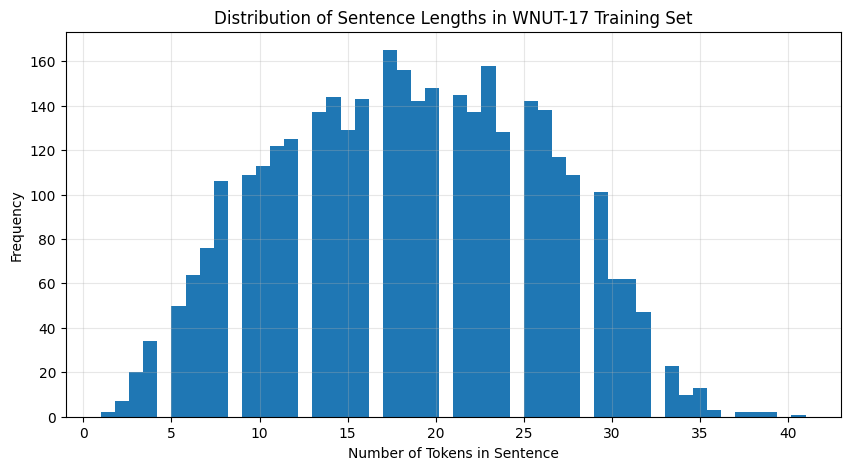

In [23]:
# sentence length distribution visualize gareko

plt.figure(figsize=(10,5))


plt.hist(
    wnut_sentence_lengths,
    bins=50
)


plt.title(
    "Distribution of Sentence Lengths in WNUT-17 Training Set"
)


plt.xlabel(
    "Number of Tokens in Sentence"
)


plt.ylabel(
    "Frequency"
)


plt.show()

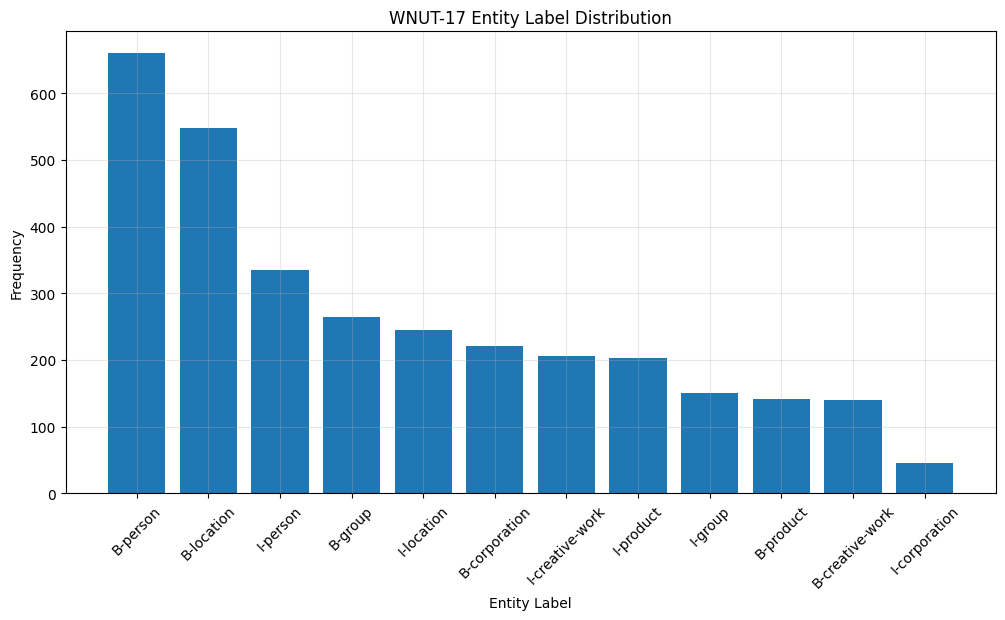

In [24]:
# all entity labels collect gareko

wnut_all_labels = [
    wnut_label_names[tag]
    for sentence in wnut_dataset['train']['ner_tags']
    for tag in sentence
]


wnut_label_counts = Counter(
    wnut_all_labels
)


# O label remove gareko

if 'O' in wnut_label_counts:
    del wnut_label_counts['O']


sorted_labels = sorted(
    wnut_label_counts.items(),
    key=lambda x:x[1],
    reverse=True
)


entity_labels, entity_counts = zip(
    *sorted_labels
)


plt.figure(figsize=(12,6))


plt.bar(
    entity_labels,
    entity_counts
)


plt.title(
    "WNUT-17 Entity Label Distribution"
)


plt.xlabel(
    "Entity Label"
)


plt.ylabel(
    "Frequency"
)


plt.xticks(
    rotation=45
)


plt.show()

In [25]:
# WNUT-17 tag IDs lai labels ma convert gareko

def sent2labels_wnut(sentence_tags):

    return [
        wnut_label_names[tag]
        for tag in sentence_tags
    ]

In [26]:
# training data ko features extract gareko

X_train_wnut = [
    sent2features(sentence)
    for sentence in wnut_dataset['train']['tokens']
]


y_train_wnut = [
    sent2labels_wnut(tags)
    for tags in wnut_dataset['train']['ner_tags']
]


# validation data prepare gareko

X_val_wnut = [
    sent2features(sentence)
    for sentence in wnut_dataset['validation']['tokens']
]


y_val_wnut = [
    sent2labels_wnut(tags)
    for tags in wnut_dataset['validation']['ner_tags']
]


# test data prepare gareko

X_test_wnut = [
    sent2features(sentence)
    for sentence in wnut_dataset['test']['tokens']
]


y_test_wnut = [
    sent2labels_wnut(tags)
    for tags in wnut_dataset['test']['ner_tags']
]


print("WNUT-17 feature extraction complete.")

WNUT-17 feature extraction complete.


In [27]:
# WNUT-17 ko lagi CRF model train gareko

wnut_crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True
)


wnut_crf.fit(
    X_train_wnut,
    y_train_wnut
)


print("WNUT-17 CRF training complete.")

WNUT-17 CRF training complete.


In [28]:
# test data ma prediction gareko

y_pred_wnut = wnut_crf.predict(
    X_test_wnut
)


# evaluation labels prepare gareko

wnut_eval_labels = list(
    wnut_crf.classes_
)


if 'O' in wnut_eval_labels:
    wnut_eval_labels.remove('O')


print(
    metrics.flat_classification_report(
        y_test_wnut,
        y_pred_wnut,
        labels=wnut_eval_labels,
        digits=3
    )
)

                 precision    recall  f1-score   support

     B-location      0.363     0.247     0.294       150
     I-location      0.414     0.128     0.195        94
        B-group      0.227     0.030     0.053       165
  B-corporation      0.500     0.015     0.029        66
       B-person      0.583     0.140     0.226       429
B-creative-work      0.286     0.028     0.051       142
      B-product      0.250     0.008     0.015       127
       I-person      0.621     0.275     0.381       131
I-creative-work      0.233     0.032     0.056       218
  I-corporation      0.500     0.045     0.083        22
        I-group      0.286     0.057     0.095        70
      I-product      0.200     0.008     0.015       126

      micro avg      0.439     0.097     0.159      1740
      macro avg      0.372     0.084     0.125      1740
   weighted avg      0.388     0.097     0.145      1740



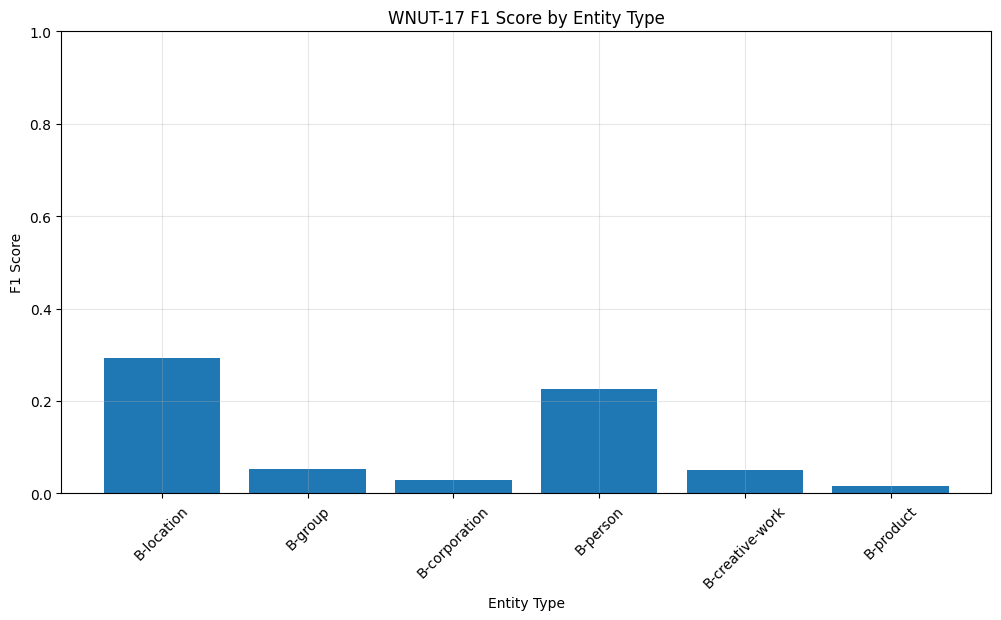

In [29]:
# classification report dictionary ma convert gareko

wnut_report = metrics.flat_classification_report(
    y_test_wnut,
    y_pred_wnut,
    labels=wnut_eval_labels,
    output_dict=True
)


entity_names = [
    label
    for label in wnut_eval_labels
    if label.startswith("B-")
]


f1_scores = [
    wnut_report[label]['f1-score']
    for label in entity_names
]


plt.figure(figsize=(12,6))


plt.bar(
    entity_names,
    f1_scores
)


plt.title(
    "WNUT-17 F1 Score by Entity Type"
)


plt.xlabel(
    "Entity Type"
)


plt.ylabel(
    "F1 Score"
)


plt.xticks(
    rotation=45
)


plt.ylim(
    0,
    1
)


plt.show()

In [30]:
# prediction error examples display gareko

error_count = 0


print(
    f"{'Token':<20} | {'True Label':<15} | {'Predicted':<15}"
)

print("="*60)


for i in range(len(y_test_wnut)):

    if y_test_wnut[i] != y_pred_wnut[i]:

        for token, true_lbl, pred_lbl in zip(
            wnut_dataset['test'][i]['tokens'],
            y_test_wnut[i],
            y_pred_wnut[i]
        ):

            if true_lbl != pred_lbl:

                print(
                    f"{token:<20} | {true_lbl:<15} | {pred_lbl:<15} <-- ERROR"
                )

            else:

                print(
                    f"{token:<20} | {true_lbl:<15} | {pred_lbl:<15}"
                )


        print("-"*60)

        error_count += 1


    if error_count >= 3:
        break

Token                | True Label      | Predicted      
&                    | O               | O              
gt                   | O               | O              
;                    | O               | O              
*                    | O               | O              
The                  | O               | O              
soldier              | O               | O              
was                  | O               | O              
killed               | O               | O              
when                 | O               | O              
another              | O               | O              
avalanche            | O               | O              
hit                  | O               | O              
an                   | O               | O              
army                 | O               | O              
barracks             | O               | O              
in                   | O               | O              
the                  | O       

## Task 6: Model Analysis on WNUT-17 Dataset

### Objective
In this task, we analyze the performance of our CRF-based Named Entity Recognition model on the WNUT-17 dataset.

Unlike CoNLL-2003, WNUT-17 contains noisy social media text with emerging entities, spelling variations, hashtags, and uncommon named entities.

The goal is to understand:
- How well CRF handles real-world noisy text
- Which entity categories are difficult
- Limitations of traditional feature-based models
- Possible improvements using modern NLP architectures


### Key Findings

1. Performance on WNUT-17

The CRF model achieved relatively low F1-scores compared to CoNLL-2003.

This happens because:
- WNUT-17 contains many unseen entities (OOV words)
- Social media text contains informal spelling and abbreviations
- Entities like products, groups, and creative works have high variation


2. Best Performing Entities

Location entities achieved the highest performance.

Reason:
- Locations often have clear capitalization patterns
- Many locations appear repeatedly in training data


3. Poor Performing Entities

Product, Corporation, and Creative Work entities showed poor performance.

Reasons:
- Many entities are new or rare
- Multi-word boundaries are difficult
- Character-based features are not enough to understand meaning


4. Error Analysis

Common errors observed:

- Missing unknown entities:
  Example:
  "Sonmarg" was a location entity but the model predicted it as O.

- Entity boundary mistakes:
  The model sometimes detects only part of a multi-word entity.

- Semantic confusion:
  Similar words can represent different entity types depending on context.


### Limitations of CRF Model

Although CRF is fast and interpretable, it has limitations:

- Requires manual feature engineering
- Cannot understand deep semantic meaning
- Struggles with unseen words
- Depends heavily on capitalization and spelling patterns


### Future Improvements

To improve performance:

1. Transformer Models

Use BERT, RoBERTa, or DeBERTa-based NER models.

Advantages:
- Learn contextual meaning automatically
- Handle ambiguous entities better
- Better performance on noisy text


2. Domain Specific Fine-Tuning

Train the model on real social media/customer data to improve domain adaptation.


3. Data Augmentation

Generate more examples for rare entity classes like:
- Product
- Corporation
- Creative Work


### Final Conclusion

The CRF model provides a strong baseline for Named Entity Recognition.

It performs well when entities have clear patterns, but struggles with noisy and unseen entities in WNUT-17.

For production-level NER systems, Transformer-based models are recommended because they provide better contextual understanding and generalization ability.

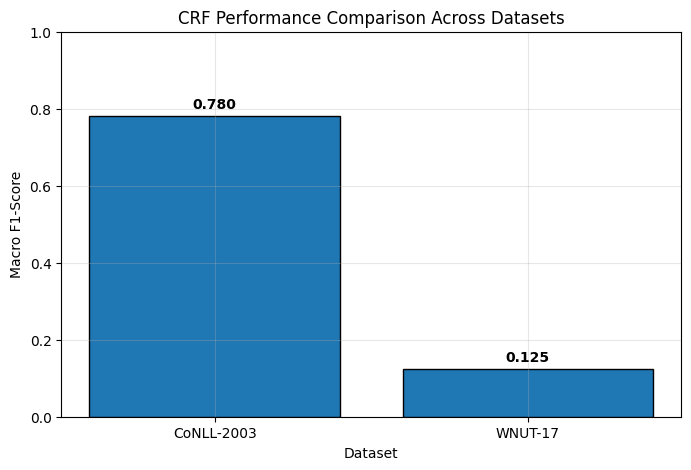

In [31]:
# Dataset comparison

datasets = ['CoNLL-2003', 'WNUT-17']

f1_scores = [
    0.780,   # CoNLL macro F1
    0.125    # WNUT macro F1
]


plt.figure(figsize=(8,5))

bars = plt.bar(
    datasets,
    f1_scores,
    edgecolor='black'
)

plt.title("CRF Performance Comparison Across Datasets")
plt.xlabel("Dataset")
plt.ylabel("Macro F1-Score")
plt.ylim(0,1)

for bar, score in zip(bars, f1_scores):
    plt.text(
        bar.get_x()+bar.get_width()/2,
        score+0.02,
        f"{score:.3f}",
        ha='center',
        fontweight='bold'
    )

plt.show()

## Interpretation of CRF Performance Comparison

The comparison shows a significant difference in CRF model performance between CoNLL-2003 and WNUT-17 datasets.

### Performance Difference

| Dataset | Macro F1-Score | Text Domain |
|---------|---------------|-------------|
| CoNLL-2003 | 0.780 | Formal News Text |
| WNUT-17 | 0.125 | Noisy Social Media Text |

### Key Observations

1. **Large Performance Drop**

The CRF model achieved a Macro F1-score of 0.780 on CoNLL-2003 but only 0.125 on WNUT-17.

This represents a major performance decrease because WNUT-17 contains:
- Informal language
- Spelling variations
- Rare and unseen entities
- Social media style text


2. **Dataset Characteristics Impact**

**CoNLL-2003:**
- Contains structured news articles
- Entities usually follow standard capitalization patterns
- Vocabulary is more consistent

Therefore, handcrafted CRF features such as:
- Prefix
- Suffix
- Capitalization
- Neighboring words

work effectively.


**WNUT-17:**
- Contains noisy user-generated content
- Many unknown entities (OOV words)
- Irregular capitalization
- Short and informal sentences

Because CRF depends on manually created features, it struggles to understand the deeper meaning of words.


3. **Effect of Macro F1-Score**

Macro F1 gives equal importance to every entity category.

In WNUT-17, rare classes such as:
- Product
- Corporation
- Creative Work

have very low F1-scores, which significantly reduces the overall Macro F1-score.


### Final Conclusion

The experiment shows that CRF is effective for structured datasets with predictable patterns but has limited ability on dynamic and noisy real-world text.

For modern NER applications, Transformer-based models such as BERT or RoBERTa are preferred because they learn contextual representations automatically and handle unseen entities better.